In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Find project root
cwd = Path.cwd()

if (cwd / "data").is_dir() and (cwd / "outputs").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data").is_dir() and (cwd.parent / "outputs").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Cannot find the HAALSI_Project data/ and outputs/ folders."
    )

DATA = PROJECT_ROOT / "data"
OUTPUTS = PROJECT_ROOT / "outputs"

FIGURES = PROJECT_ROOT / "figures" / "supervisor"
FIGURES.mkdir(parents=True, exist_ok=True)

# Load datasets from data/ and results from outputs/
def load_csv(prefix):
    for folder in [DATA, OUTPUTS]:
        matches = sorted(
            folder.glob(f"{prefix}*.csv"),
            key=lambda p: p.stat().st_mtime,
            reverse=True
        )

        if matches:
            df = pd.read_csv(matches[0])
            print(
                f"Loaded [{folder.name}]: {matches[0].name} "
                f"({df.shape[0]:,} rows × {df.shape[1]} columns)"
            )
            return df

    print(f"Not found: {prefix}")
    return None


def get_col(df, *names):
    if df is None:
        return None

    lookup = {str(c).lower(): c for c in df.columns}

    for name in names:
        if name.lower() in lookup:
            return lookup[name.lower()]

    return None


def save_figure(name):
    plt.tight_layout()
    plt.savefig(
        FIGURES / f"{name}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


print("Project root:", PROJECT_ROOT)
print("Datasets in data/:", len(list(DATA.glob("*.csv"))))
print("Results in outputs/:", len(list(OUTPUTS.glob("*.csv"))))

Project root: c:\Users\kwane\Downloads\HAALSI_Project
Datasets in data/: 3
Results in outputs/: 95


In [2]:
longitudinal = load_csv("HAALSI_Longitudinal_SPC_Dataset")
narrowed = load_csv("HAALSI_Narrowed_SPC_Dataset")
paired = load_csv("HAALSI_Paired_Delayed_Recall_Analysis")

datasets = {
    "Longitudinal": longitudinal,
    "SPC analysis": narrowed,
    "Paired prediction": paired,
}

summary = []

for name, df in datasets.items():
    if df is None:
        continue

    participant = get_col(df, "prim_key", "participant_id")

    summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Unique participants": (
            df[participant].nunique() if participant else np.nan
        ),
        "Columns": df.shape[1],
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

Loaded [data]: HAALSI_Longitudinal_SPC_Dataset.csv (805 rows × 65 columns)
Loaded [data]: HAALSI_Narrowed_SPC_Dataset.csv (1,318 rows × 33 columns)
Loaded [data]: HAALSI_Paired_Delayed_Recall_Analysis.csv (504 rows × 65 columns)


,Dataset,Rows,Unique participants,Columns
0,Longitudinal,805,805,65
1,SPC analysis,1318,805,33
2,Paired prediction,504,504,65


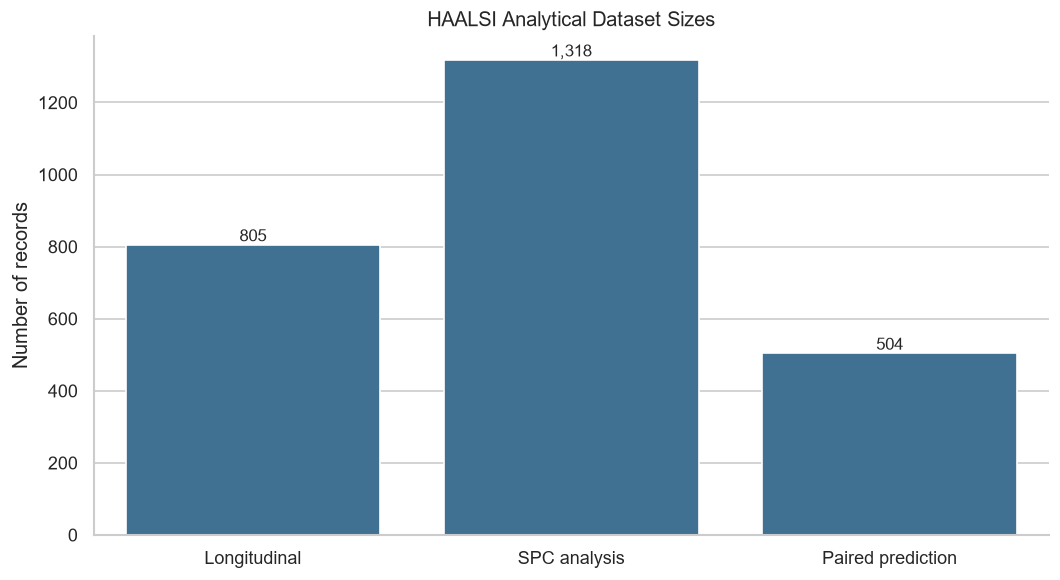

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=summary_df,
    x="Dataset",
    y="Rows",
    color="#3274A1",
    ax=ax
)

for bar in ax.patches:
    ax.annotate(
        f"{bar.get_height():,.0f}",
        (bar.get_x() + bar.get_width()/2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_title("HAALSI Analytical Dataset Sizes")
ax.set_ylabel("Number of records")
ax.set_xlabel("")
save_figure("01_analytical_sample_sizes")

,Records
education_level,
1.0,747
2.0,433
3.0,79
4.0,57
NaN,2


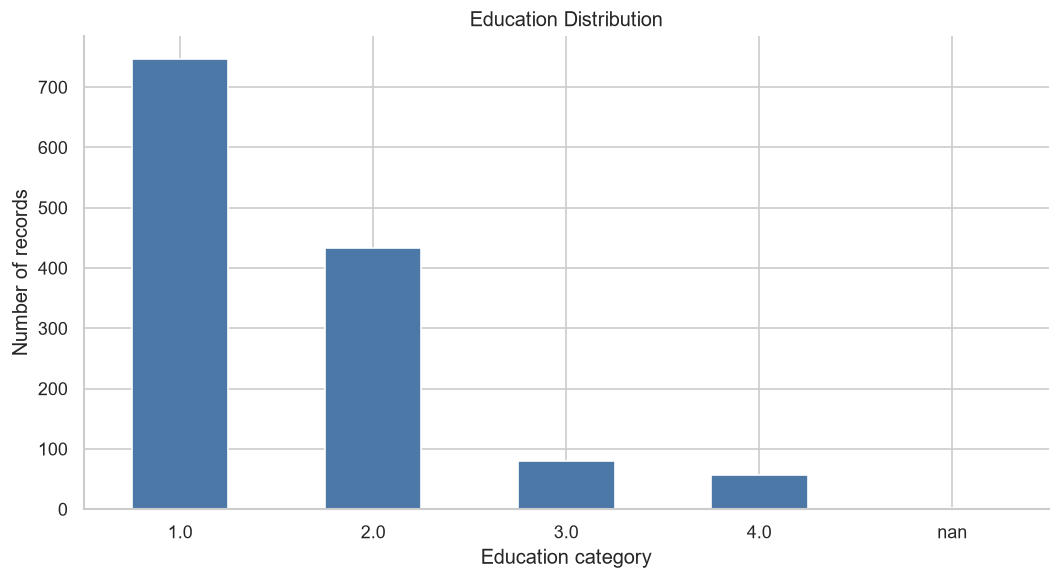

In [4]:
df = narrowed if narrowed is not None else longitudinal

education_col = get_col(
    df, "education_level", "education", "education_group"
)

if education_col:
    education_counts = (
        df[education_col]
        .value_counts(dropna=False)
        .sort_index()
    )

    display(education_counts.to_frame("Records"))

    ax = education_counts.plot(
        kind="bar",
        figsize=(9, 5),
        color="#4C78A8"
    )

    ax.set_title("Education Distribution")
    ax.set_xlabel("Education category")
    ax.set_ylabel("Number of records")
    plt.xticks(rotation=0)
    save_figure("02_education_distribution")
else:
    print("Education column not found.")
    print(df.columns.tolist())

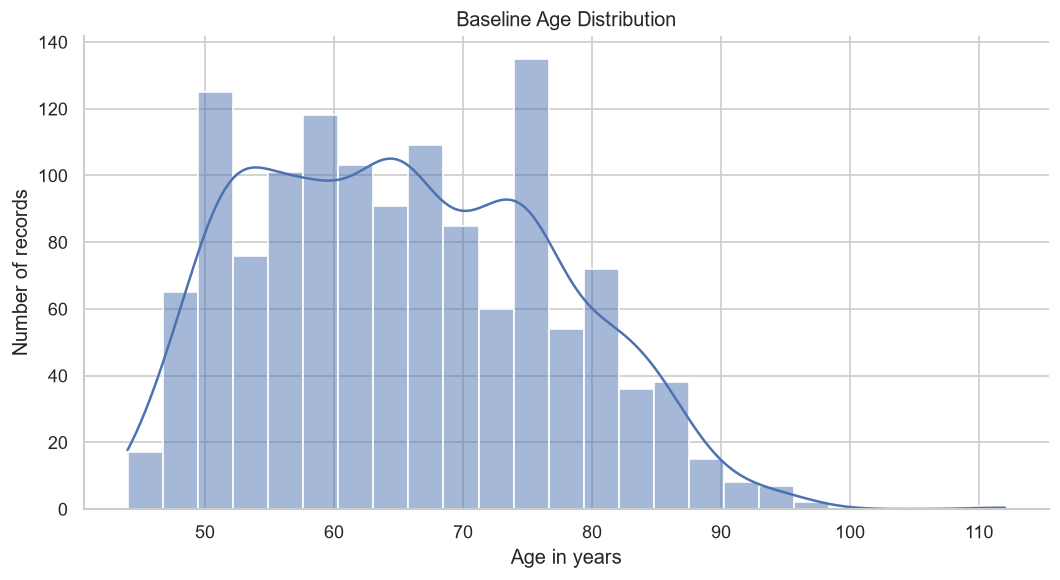

count    1318.000000
mean       65.446889
std        11.471657
min        44.000000
25%        56.000000
50%        65.000000
75%        74.000000
max       112.000000
Name: age_baseline, dtype: float64

In [5]:
age_col = get_col(
    df, "age_baseline", "age", "w1c_rage_calc"
)

if age_col:
    ages = pd.to_numeric(df[age_col], errors="coerce")

    fig, ax = plt.subplots(figsize=(9, 5))
    sns.histplot(ages.dropna(), bins=25, kde=True, ax=ax)

    ax.set_title("Baseline Age Distribution")
    ax.set_xlabel("Age in years")
    ax.set_ylabel("Number of records")

    save_figure("03_age_distribution")

    display(ages.describe())
else:
    print("Age column not found.")

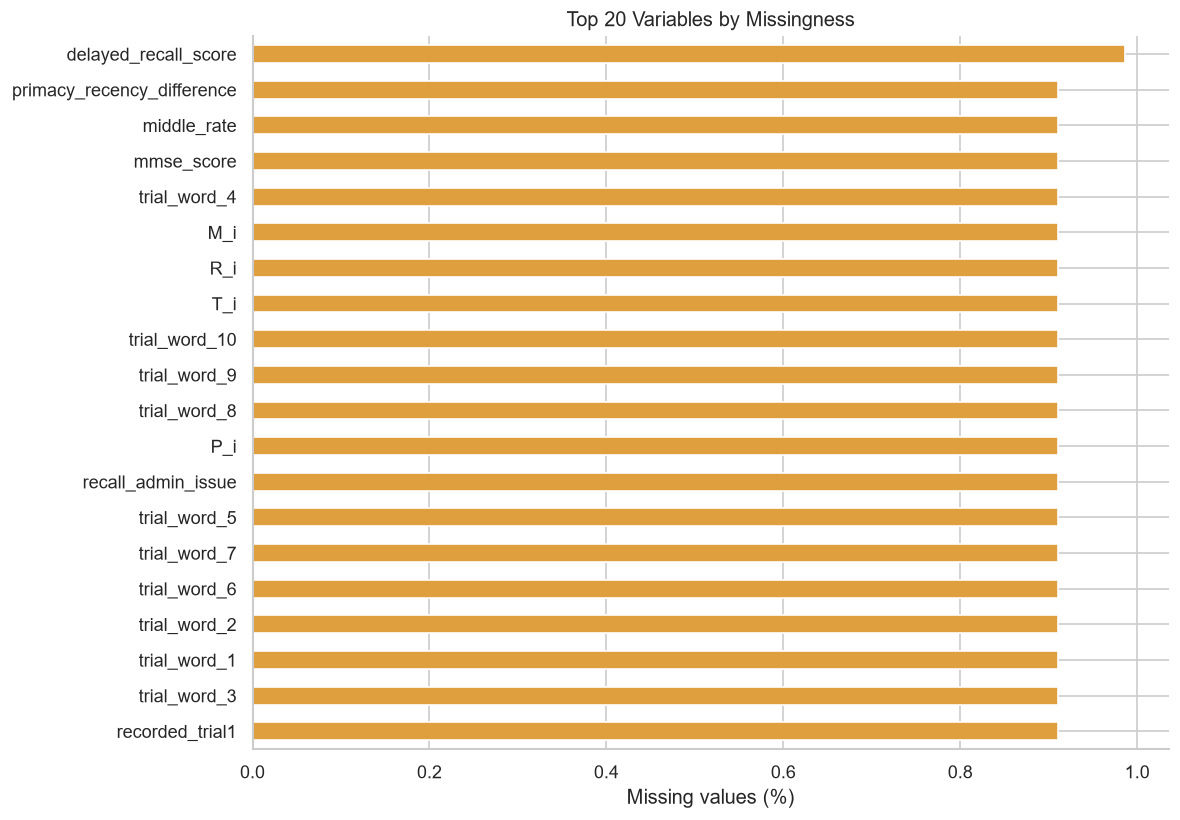

,Missing (%)
delayed_recall_score,0.986343
recorded_trial1,0.910470
trial_word_3,0.910470
trial_word_1,0.910470
trial_word_2,0.910470
trial_word_7,0.910470
trial_word_6,0.910470
trial_word_5,0.910470
recall_admin_issue,0.910470
trial_word_8,0.910470


In [6]:
missing = (
    df.isna().mean()
    .mul(100)
    .sort_values(ascending=False)
)

top_missing = missing.head(20).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
top_missing.plot(kind="barh", ax=ax, color="#E09F3E")

ax.set_title("Top 20 Variables by Missingness")
ax.set_xlabel("Missing values (%)")

save_figure("04_missingness")

display(missing.to_frame("Missing (%)").head(20))